# ESS 배터리 Cycle Life 예측 - DAY 2 피처 엔지니어링

## 목적
초기 100사이클에서 얻을 수 있는 정보만 사용하여, **배터리 셀 1개 = 표의 1행**인 회귀 모델 입력 데이터를 만듭니다.  
Target은 `cycle_life`이며, Batch 1은 모델 개발용, Batch 2는 최종 Test용으로 유지합니다.

이 노트북에서는 다음 작업만 수행합니다.

1. Batch 1·2 데이터와 Target 유효 셀 확인
2. DAY 1 EDA 근거에 따라 초기 피처 구성
3. 충전정책 문자열에서 수치 피처 추출
4. 미래 정보를 포함한 누수 피처 제외
5. 자료형·결측치·무한대·상수 피처 점검
6. 모델링용 표와 피처 명세 저장

> 결측값 대체, 표준화, 모델 학습과 하이퍼파라미터 조정은 `03_modeling.ipynb`의 Pipeline 안에서 Train 데이터에만 맞춰 수행합니다.

## 0. 실행 환경 설정

프로젝트 루트를 자동으로 찾은 뒤 DAY 1에서 검증한 데이터 로딩 함수 `load_batches()`를 재사용합니다. 동일한 로딩 함수를 사용하면 DAY 1과 DAY 2의 셀 정의와 피처 계산 방식이 달라지는 것을 막을 수 있습니다.

In [2]:
import os
import re
import sys
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/da_mpl_cache')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p / 'src' / 'day1_eda.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.day1_eda import load_batches

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.max_columns', 100)

print('프로젝트 폴더:', ROOT)
print('Python:', sys.executable)

프로젝트 폴더: /Users/jiyong/Desktop/DA
Python: /Users/jiyong/Desktop/DA/.venv311/bin/python


## 1. 원본 데이터 불러오기와 분석 단위 확인

원본 MATLAB 파일에서 Batch 1·2·3을 읽습니다. `df`의 한 행은 한 번의 Cycle이 아니라 **서로 다른 배터리 셀 하나**입니다. 모델의 예측 단위도 배터리 셀이므로 같은 셀의 여러 Cycle을 서로 다른 표본처럼 분리하지 않습니다.

In [3]:
df, curves, voltage_grids = load_batches()

print(f'전체 데이터: {df.shape[0]}셀 × {df.shape[1]}열')
display(
    df.groupby('batch', sort=False)
      .agg(전체_셀=('cell_id', 'size'), Cycle_Life_유효=('cycle_life', 'count'))
)
display(df[['batch', 'cell_id', 'policy', 'cycle_life']].head())

전체 데이터: 139셀 × 34열


,전체_셀,Cycle_Life_유효
batch,,
Batch 1,46,46
Batch 2,47,39
Batch 3,46,44


,batch,cell_id,policy,cycle_life
0,Batch 1,Batch1_C01,3.6C(80%)-3.6C,1190.0
1,Batch 1,Batch1_C02,3.6C(80%)-3.6C,1179.0
2,Batch 1,Batch1_C03,3.6C(80%)-3.6C,1177.0
3,Batch 1,Batch1_C04,4C(80%)-4C,1226.0
4,Batch 1,Batch1_C05,4C(80%)-4C,1227.0


### 판단

- 과제의 필수 Modeling은 **Batch 1 학습, Batch 2 Test**입니다.
- Batch 3 평가는 선택사항이므로 이번 필수 모델링 표에서는 제외합니다.
- `cycle_life`가 결측인 셀은 정답이 없어 지도학습에 사용할 수 없으므로 제외합니다.
- 제외는 오류 셀을 임의로 지우는 것이 아니라, 정답이 필요한 지도학습의 필수 조건입니다.

In [4]:
model_source = df[
    df['batch'].isin(['Batch 1', 'Batch 2'])
    & df['cycle_life'].notna()
].copy()

assert model_source['cell_id'].is_unique, 'cell_id 중복을 확인하세요.'
assert set(model_source['batch']) == {'Batch 1', 'Batch 2'}

display(model_source.groupby('batch', sort=False).size().rename('모델링_가능_셀'))
print('총 모델링 가능 셀:', len(model_source))

batch
Batch 1    46
Batch 2    39
Name: 모델링_가능_셀, dtype: int64

총 모델링 가능 셀: 85


## 2. DAY 1 EDA를 피처 설계로 연결

피처는 단순히 많이 만드는 것이 아니라 DAY 1에서 확인한 현상과 연결하여 구성합니다.

| 피처 그룹 | DAY 1에서 확인한 내용 | 모델에 제공하는 정보 |
|---|---|---|
| ΔQ(V) | Cycle 100−10의 변화가 Cycle Life와 가장 강하고 Batch별 방향도 일관됨 | 초기 방전곡선 형태 변화 |
| QD | 초기 방전용량 변화만으로 전체 수명을 충분히 설명하지는 못하지만 열화 추세를 보완 | 초기 용량과 감소 속도 |
| IR | 내부저항 증가는 열화와 연결될 가능성이 있음 | 저항 수준과 변화량 |
| 온도 | 높은 온도는 열화 반응을 가속할 가능성이 있음 | 초기 열적 조건 |
| 충전시간·C-rate | 첫 C-rate 단독 상관은 약하지만 충전 조건을 보완 | 운전 조건 |

모든 값은 실제 운영에서 예측 시점인 Cycle 100까지 알 수 있는 정보만 사용합니다.

## 3. 충전정책 문자열을 수치형 피처로 변환

예를 들어 `4.8C(80%)-3.6C`는 80% SOC까지 4.8C로 충전하고 이후 3.6C로 충전한다는 의미입니다. 문자열 자체를 셀마다 별도 범주로 사용하면 표본이 작은 상황에서 희소한 변수가 너무 많아질 수 있으므로, 물리적으로 해석 가능한 세 숫자 `first_c_rate`, `switch_soc`, `second_c_rate`로 분해합니다.

`newstructure` 표시는 Batch 1에는 존재하지 않아 Batch 1에서 효과를 학습할 수 없으므로 입력 피처로 사용하지 않습니다.

또한 일부 Batch 2 셀은 초기 100사이클의 IR 전체가 `0 Ω`로 저장되어 있습니다. 이는 실제 저항이라기보다 미측정 값을 0으로 채운 것으로 판단하여 `NaN`으로 바꿉니다. 해당 셀을 삭제하지 않고, 다음 노트북의 Pipeline이 Batch 1 Train 중앙값으로 대체하도록 남겨둡니다.

In [5]:
def parse_charging_policy(policy):
    """충전정책 문자열에서 1차 C-rate, 전환 SOC, 2차 C-rate를 추출한다."""
    pattern = r'([0-9]+(?:\.[0-9]+)?)C\(([0-9]+(?:\.[0-9]+)?)%\)-([0-9]+(?:\.[0-9]+)?)C'
    match = re.search(pattern, str(policy))
    if match is None:
        return pd.Series([np.nan, np.nan, np.nan])
    return pd.Series([float(value) for value in match.groups()])

model_source[['policy_first_c_rate', 'policy_switch_soc', 'policy_second_c_rate']] = (
    model_source['policy'].apply(parse_charging_policy)
)

policy_check = model_source[[
    'batch', 'cell_id', 'policy', 'policy_first_c_rate',
    'policy_switch_soc', 'policy_second_c_rate'
]]
display(policy_check.head(10))
print('정책 파싱 실패:', int(policy_check['policy_first_c_rate'].isna().sum()), '셀')

# IR 10·100이 모두 0인 경우: 실제 0Ω가 아니라 미측정 표기로 판단
invalid_ir_mask = model_source['ir_10'].le(0) & model_source['ir_100'].le(0)
ir_features = ['ir_10', 'ir_100', 'ir_delta_100_10']
model_source.loc[invalid_ir_mask, ir_features] = np.nan

print('IR 미측정으로 NaN 처리한 셀:', int(invalid_ir_mask.sum()), '개')
display(model_source.loc[invalid_ir_mask, ['batch', 'cell_id', *ir_features]])

,batch,cell_id,policy,policy_first_c_rate,policy_switch_soc,policy_second_c_rate
0,Batch 1,Batch1_C01,3.6C(80%)-3.6C,3.6,80.0,3.6
1,Batch 1,Batch1_C02,3.6C(80%)-3.6C,3.6,80.0,3.6
2,Batch 1,Batch1_C03,3.6C(80%)-3.6C,3.6,80.0,3.6
3,Batch 1,Batch1_C04,4C(80%)-4C,4.0,80.0,4.0
4,Batch 1,Batch1_C05,4C(80%)-4C,4.0,80.0,4.0
5,Batch 1,Batch1_C06,4.4C(80%)-4.4C,4.4,80.0,4.4
6,Batch 1,Batch1_C07,4.8C(80%)-4.8C,4.8,80.0,4.8
7,Batch 1,Batch1_C08,4.8C(80%)-4.8C,4.8,80.0,4.8
8,Batch 1,Batch1_C09,5.4C(40%)-3.6C,5.4,40.0,3.6
9,Batch 1,Batch1_C10,5.4C(40%)-3.6C,5.4,40.0,3.6


정책 파싱 실패: 0 셀
IR 미측정으로 NaN 처리한 셀: 6 개


,batch,cell_id,ir_10,ir_100,ir_delta_100_10
87,Batch 2,Batch2_C42,NaN,NaN,NaN
88,Batch 2,Batch2_C43,NaN,NaN,NaN
89,Batch 2,Batch2_C44,NaN,NaN,NaN
90,Batch 2,Batch2_C45,NaN,NaN,NaN
91,Batch 2,Batch2_C46,NaN,NaN,NaN
92,Batch 2,Batch2_C47,NaN,NaN,NaN


## 4. 후보 피처와 최종 입력 피처 정의

ΔQ 계열은 서로 강하게 상관되어 있으므로 모든 통계량을 무조건 투입하지 않습니다. DAY 1에서 Batch별 관계가 비교적 일관됐던 `dq_log_var`, `dq_min`을 핵심 피처로 선택하고, QD·IR·온도·충전시간·충전정책을 보조 피처로 구성합니다.

`cell_id`, `batch`, `policy`는 추적·분할·오류분석용 메타데이터이며 모델 입력값은 아닙니다.

In [6]:
feature_groups = {
    'delta_q_core': ['dq_log_var', 'dq_min'],
    'capacity': ['qd_10', 'qd_100', 'qd_delta_100_10', 'qd_slope_10_100'],
    'resistance': ['ir_10', 'ir_100', 'ir_delta_100_10'],
    'temperature': ['mean_tavg_100', 'mean_tmax_100'],
    'charge_condition': [
        'mean_chargetime_100', 'policy_first_c_rate',
        'policy_switch_soc', 'policy_second_c_rate'
    ],
}

feature_columns = [
    feature
    for group_features in feature_groups.values()
    for feature in group_features
]

metadata_columns = ['batch', 'cell_id', 'policy']
target_column = 'cycle_life'

print('입력 피처 수:', len(feature_columns))
for group, columns in feature_groups.items():
    print(f'- {group}: {columns}')

입력 피처 수: 15
- delta_q_core: ['dq_log_var', 'dq_min']
- capacity: ['qd_10', 'qd_100', 'qd_delta_100_10', 'qd_slope_10_100']
- resistance: ['ir_10', 'ir_100', 'ir_delta_100_10']
- temperature: ['mean_tavg_100', 'mean_tmax_100']
- charge_condition: ['mean_chargetime_100', 'policy_first_c_rate', 'policy_switch_soc', 'policy_second_c_rate']


## 5. Target leakage 점검

예측 시점인 Cycle 100에는 알 수 없는 미래 정보를 입력하면 실제로 사용할 수 없는 모델이 만들어집니다. 다음 변수는 분석·설명에는 사용할 수 있지만 모델의 `X`에서는 제외합니다.

- `cycle_life`: 모델이 맞혀야 할 정답이므로 `y`로만 사용
- `log_cycle_life`: Target을 변환한 값이므로 `y`로만 사용 가능
- `knee_cycle`, `knee_fraction`: 전체 열화곡선을 봐야 계산 가능
- `n_recorded_cycles`: 실험이 끝난 뒤 알 수 있으며 Cycle Life와 직접 연결
- 최종 QD 또는 Cycle 100 이후 값: 예측 시점 이후의 미래 정보

아래 검사는 누수 컬럼이 입력 피처 목록에 잘못 포함되지 않았는지 코드로 확인합니다.

In [7]:
leakage_columns = {
    'cycle_life', 'log_cycle_life', 'knee_cycle',
    'knee_fraction', 'n_recorded_cycles'
}
leakage_found = sorted(leakage_columns.intersection(feature_columns))

assert not leakage_found, f'입력 피처에서 누수 변수 발견: {leakage_found}'
assert set(feature_columns).issubset(model_source.columns), '존재하지 않는 피처가 있습니다.'
print('누수 점검 통과: 미래 정보가 입력 피처에 포함되지 않았습니다.')

누수 점검 통과: 미래 정보가 입력 피처에 포함되지 않았습니다.


## 6. 모델링용 표 생성

모델링 표에는 메타데이터, 입력 피처, Target만 남깁니다. 모델 학습 시에는 `feature_columns`만 `X`로 사용하고, `cycle_life`를 `y`로 사용합니다.

In [13]:
model_table = model_source[metadata_columns + feature_columns + [target_column]].copy()
model_table = model_table.sort_values(['batch', 'cell_id']).reset_index(drop=True)

print(f'모델링 표: {model_table.shape[0]}셀 × {model_table.shape[1]}열')
display(model_table.head())

모델링 표: 85셀 × 19열


,batch,cell_id,policy,dq_log_var,dq_min,qd_10,qd_100,qd_delta_100_10,qd_slope_10_100,ir_10,ir_100,ir_delta_100_10,mean_tavg_100,mean_tmax_100,mean_chargetime_100,policy_first_c_rate,policy_switch_soc,policy_second_c_rate,cycle_life
0,Batch 1,Batch1_C01,3.6C(80%)-3.6C,-5.014861,-0.008460,1.074537,1.075913,0.001375,-0.000314,0.016572,0.016667,0.000095,31.287710,35.022981,13.250388,3.6,80.0,3.6,1190.0
1,Batch 1,Batch1_C02,3.6C(80%)-3.6C,-5.013960,-0.011004,1.079777,1.080630,0.000853,-0.000014,0.016868,0.016997,0.000129,31.017011,33.819048,13.240949,3.6,80.0,3.6,1179.0
2,Batch 1,Batch1_C03,3.6C(80%)-3.6C,-4.737000,-0.017216,1.083782,1.084940,0.001159,-0.000005,0.016687,0.016854,0.000167,31.164788,34.199197,13.245097,3.6,80.0,3.6,1177.0
3,Batch 1,Batch1_C04,4C(80%)-4C,-4.442613,-0.018961,1.084308,1.084750,0.000442,0.000006,0.016208,0.016408,0.000201,29.642777,30.355641,11.932744,4.0,80.0,4.0,1226.0
4,Batch 1,Batch1_C05,4C(80%)-4C,-4.647744,-0.013958,1.081954,1.082646,0.000692,0.000008,0.016616,0.016734,0.000118,31.134395,34.038691,11.932781,4.0,80.0,4.0,1227.0


## 7. 피처 품질 점검

모델 학습 전에 숫자형 여부, 결측치, 무한대, 고유값 수를 확인합니다. 여기서는 결측값을 전체 데이터 평균으로 미리 채우지 않습니다. 실제 대체 기준은 `03_modeling.ipynb`에서 Train 데이터로만 학습해야 Test 정보가 섞이지 않습니다.

In [9]:
quality_rows = []
for feature in feature_columns:
    values = pd.to_numeric(model_table[feature], errors='coerce')
    quality_rows.append({
        'feature': feature,
        'dtype': str(model_table[feature].dtype),
        'missing_n': int(values.isna().sum()),
        'missing_pct': values.isna().mean() * 100,
        'infinite_n': int(np.isinf(values).sum()),
        'unique_n': int(values.nunique(dropna=True)),
        'min': values.replace([np.inf, -np.inf], np.nan).min(),
        'median': values.replace([np.inf, -np.inf], np.nan).median(),
        'max': values.replace([np.inf, -np.inf], np.nan).max(),
    })

feature_quality = pd.DataFrame(quality_rows)
display(feature_quality.round(4))

print('숫자형이 아닌 피처:', [c for c in feature_columns if not pd.api.types.is_numeric_dtype(model_table[c])])
print('결측치가 있는 피처:', feature_quality.loc[feature_quality.missing_n > 0, 'feature'].tolist())
print('무한대가 있는 피처:', feature_quality.loc[feature_quality.infinite_n > 0, 'feature'].tolist())
print('상수 피처:', feature_quality.loc[feature_quality.unique_n <= 1, 'feature'].tolist())

,feature,dtype,missing_n,missing_pct,infinite_n,unique_n,min,median,max
0,dq_log_var,float64,0,0.0000,0,85,-5.0149,-3.6739,-3.0859
1,dq_min,float64,0,0.0000,0,85,-0.0862,-0.0441,-0.0085
2,qd_10,float64,0,0.0000,0,85,1.0581,1.0866,1.1099
3,qd_100,float64,0,0.0000,0,85,1.0600,1.0849,1.1163
4,qd_delta_100_10,float64,0,0.0000,0,85,-0.0227,-0.0006,0.0105
5,qd_slope_10_100,float64,0,0.0000,0,85,-0.0005,-0.0000,0.0001
6,ir_10,float64,6,7.0588,0,79,0.0148,0.0166,0.0199
7,ir_100,float64,6,7.0588,0,79,0.0148,0.0167,0.0178
8,ir_delta_100_10,float64,6,7.0588,0,79,-0.0040,0.0001,0.0004
9,mean_tavg_100,float64,0,0.0000,0,85,29.6428,32.7467,35.6658


숫자형이 아닌 피처: []
결측치가 있는 피처: ['ir_10', 'ir_100', 'ir_delta_100_10']
무한대가 있는 피처: []
상수 피처: []


## 8. 다중공선성과 피처 중복 확인

절댓값 상관계수가 매우 높은 피처를 동시에 사용하면 선형회귀 계수가 불안정해질 수 있습니다. 아래 표는 제거를 자동 결정하는 것이 아니라, Ridge·ElasticNet 정규화가 필요한 근거와 피처 축소 후보를 확인하기 위한 진단입니다.

> 이 단계에서는 Batch 1만 사용합니다. Batch 2의 Target 관계를 보고 피처를 선택하면 Test 정보가 모델 설계에 반영될 수 있기 때문입니다.

In [14]:
batch1_features = model_table.loc[
    model_table['batch'].eq('Batch 1'), feature_columns
]
corr_matrix = batch1_features.corr(method='spearman')

high_corr_pairs = []
for i, left in enumerate(feature_columns):
    for right in feature_columns[i + 1:]:
        value = corr_matrix.loc[left, right]
        if pd.notna(value) and abs(value) >= 0.85:
            high_corr_pairs.append({
                'feature_1': left, 'feature_2': right,
                'spearman': value, 'abs_spearman': abs(value)
            })

high_corr_pairs = pd.DataFrame(high_corr_pairs)
if len(high_corr_pairs):
    display(high_corr_pairs.sort_values('abs_spearman', ascending=False).round(3))
else:
    print('|Spearman| ≥ 0.85인 피처 쌍이 없습니다.')

,feature_1,feature_2,spearman,abs_spearman
0,dq_log_var,dq_min,-0.987,0.987
2,mean_tavg_100,mean_tmax_100,0.951,0.951
1,qd_10,qd_100,0.928,0.928
3,policy_first_c_rate,policy_switch_soc,-0.869,0.869


## 9. Batch 1과 Batch 2 입력 분포 비교

Batch 1에서 학습한 모델을 Batch 2에 적용하므로 입력 분포 차이를 확인합니다. 이 확인은 Test 정답을 이용해 모델을 선택하려는 것이 아니라, 나중에 Valid−Test 성능 차이가 발생했을 때 원인을 해석하기 위한 자료입니다.

아래에서는 각 Batch의 중앙값과 IQR을 비교합니다. 중앙값 차이가 크거나 IQR이 겹치지 않는 피처는 Batch shift 가능성이 있습니다.

batch,Batch 1,Batch 2
dq_log_var_median,-3.8512,-3.4873
dq_log_var_q1,-4.0534,-3.6741
dq_log_var_q3,-3.6682,-3.3356
dq_min_median,-0.0364,-0.0542
dq_min_q1,-0.0446,-0.0646
dq_min_q3,-0.0286,-0.0427
qd_10_median,1.0821,1.0984
qd_10_q1,1.0783,1.0915
qd_10_q3,1.0857,1.1020
qd_100_median,1.0815,1.0975


findfont: Failed to find font weight bold for AppleGothic, now using 400.


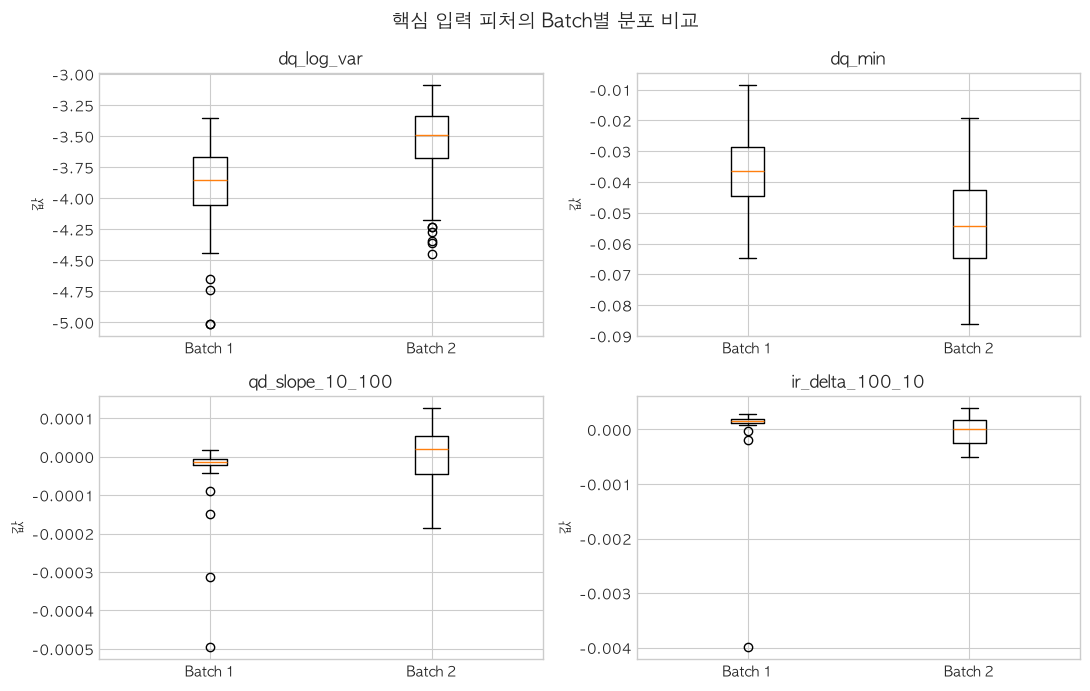

In [11]:
def q1(values):
    return values.quantile(0.25)

def q3(values):
    return values.quantile(0.75)

batch_distribution = (
    model_table.groupby('batch', sort=False)[feature_columns]
    .agg(['median', q1, q3])
)
batch_distribution.columns = [
    f'{feature}_{stat}'
    for feature, stat in batch_distribution.columns
]
display(batch_distribution.T.round(4))

plot_features = ['dq_log_var', 'dq_min', 'qd_slope_10_100', 'ir_delta_100_10']
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, feature in zip(axes.flat, plot_features):
    groups = [
        model_table.loc[model_table['batch'].eq(batch), feature].dropna()
        for batch in ['Batch 1', 'Batch 2']
    ]
    ax.boxplot(groups, tick_labels=['Batch 1', 'Batch 2'], showfliers=True)
    ax.set_title(feature)
    ax.set_ylabel('값')
fig.suptitle('핵심 입력 피처의 Batch별 분포 비교', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 관찰 결과 및 해석

- 핵심 피처 `dq_log_var`의 중앙값은 Batch 1 `-3.851`, Batch 2 `-3.487`로 Batch 2가 더 높았습니다. `dq_min` 중앙값도 Batch 1 `-0.036`, Batch 2 `-0.054`로 차이가 나타났습니다. 따라서 가장 중요한 ΔQ 신호부터 Batch 간 입력 분포가 동일하지 않습니다.
- 초기 방전용량도 Batch 2가 높았습니다. `qd_10` 중앙값은 Batch 1 `1.082 Ah`, Batch 2 `1.098 Ah`이고, `qd_100`도 각각 `1.082 Ah`, `1.098 Ah`였습니다. 절대 용량 수준을 사용할 경우 Batch 특성을 함께 학습할 위험이 있습니다.
- IR 중앙값은 두 Batch 모두 약 `0.016~0.017 Ω`로 비교적 유사했습니다. 다만 Batch 2의 6셀은 초기 100사이클 IR 전체가 0으로 기록되어 미측정값으로 판단하고 `NaN` 처리했습니다. 이 값은 모델 Pipeline에서 Batch 1 Train 중앙값으로 대체해야 합니다.
- 평균온도는 Batch 2가 약간 높지만 IQR이 상당 부분 겹쳤습니다. 반면 평균 충전시간은 Batch 1 IQR이 약 `10.06~11.84분`, Batch 2 IQR이 약 `10.17~29.75분`으로 Batch 2의 변동 폭이 훨씬 컸습니다.
- 충전정책도 차이가 있었습니다. 첫 C-rate 중앙값은 Batch 1 `6.0C`, Batch 2 `5.2C`, 두 번째 C-rate 중앙값은 각각 `3.6C`, `4.5C`였습니다.
- 이러한 ΔQ·초기용량·충전시간·충전정책의 분포 차이는 Batch 1에서 학습한 관계가 Batch 2에 그대로 적용되지 않는 Batch shift로 이어질 가능성이 있습니다. 다만 이 단계에서는 성능 저하의 원인이라고 확정하지 않고, `03_modeling.ipynb`에서 Valid−Test Gap과 셀별 오차를 확인한 뒤 연결하여 해석합니다.
- Batch 2 분포를 확인했더라도 Batch 2의 정답과 성능을 기준으로 피처를 제거하거나 다시 튜닝하지 않습니다. 그렇게 하면 Test 정보가 모델 선택에 반영되어 최종 성능을 공정하게 평가할 수 없기 때문입니다.

## 10. 모델링 데이터와 피처 명세 저장

`03_modeling.ipynb`가 같은 입력 데이터를 사용하도록 모델링 표를 CSV로 저장합니다. 함께 저장하는 피처 명세에는 각 피처의 그룹과 선택 근거를 기록하여 EDA → 전략 → 구현의 연결을 남깁니다.

In [15]:
feature_reason = {
    'delta_q_core': 'DAY 1에서 Cycle Life와 강하고 Batch별 방향이 일관된 ΔQ(V) 신호',
    'capacity': '초기 방전용량 수준과 Cycle 10~100의 감소 추세',
    'resistance': '초기 내부저항 수준과 변화량',
    'temperature': '초기 100사이클의 열적 운전 조건',
    'charge_condition': '충전시간과 충전 프로토콜의 수치형 조건',
}

manifest_rows = []
for group, columns in feature_groups.items():
    for feature in columns:
        manifest_rows.append({
            'feature': feature,
            'group': group,
            'available_by_cycle': 100,
            'selection_reason': feature_reason[group],
        })
feature_manifest = pd.DataFrame(manifest_rows)

output_dir = ROOT / 'output' / 'day2'
output_dir.mkdir(parents=True, exist_ok=True)
model_path = output_dir / 'model_features.csv'
manifest_path = output_dir / 'feature_manifest.csv'

model_table.to_csv(model_path, index=False)
feature_manifest.to_csv(manifest_path, index=False)

print('모델링 데이터:', model_path)
print('피처 명세:', manifest_path)
display(feature_manifest)

모델링 데이터: /Users/jiyong/Desktop/DA/output/day2/model_features.csv
피처 명세: /Users/jiyong/Desktop/DA/output/day2/feature_manifest.csv


,feature,group,available_by_cycle,selection_reason
0,dq_log_var,delta_q_core,100,DAY 1에서 Cycle Life와 강하고 Batch별 방향이 일관된 ΔQ(V) 신호
1,dq_min,delta_q_core,100,DAY 1에서 Cycle Life와 강하고 Batch별 방향이 일관된 ΔQ(V) 신호
2,qd_10,capacity,100,초기 방전용량 수준과 Cycle 10~100의 감소 추세
3,qd_100,capacity,100,초기 방전용량 수준과 Cycle 10~100의 감소 추세
4,qd_delta_100_10,capacity,100,초기 방전용량 수준과 Cycle 10~100의 감소 추세
5,qd_slope_10_100,capacity,100,초기 방전용량 수준과 Cycle 10~100의 감소 추세
6,ir_10,resistance,100,초기 내부저항 수준과 변화량
7,ir_100,resistance,100,초기 내부저항 수준과 변화량
8,ir_delta_100_10,resistance,100,초기 내부저항 수준과 변화량
9,mean_tavg_100,temperature,100,초기 100사이클의 열적 운전 조건


## 11. 피처 엔지니어링 결론

1. **분석 단위**: 배터리 셀 1개를 1개 표본으로 구성했습니다.
2. **Target**: 연속형 변수 `cycle_life`를 예측하는 Regression 문제입니다.
3. **핵심 피처**: DAY 1에서 수명과 강하고 일관된 관계를 보인 `dq_log_var`, `dq_min`입니다.
4. **보조 피처**: 초기 QD·IR 변화, 온도, 충전시간, 충전정책의 수치 조건을 사용합니다.
5. **누수 방지**: Knee, 전체 기록 길이, 최종 용량과 Cycle 100 이후 정보는 제외했습니다.
6. **전처리 원칙**: 결측값 대체와 표준화는 전체 데이터에 미리 적용하지 않고 다음 노트북의 Pipeline에서 Train 데이터에만 fit합니다.
7. **Batch shift 관찰**: Batch 2는 Batch 1보다 `dq_log_var`, 초기 QD, 충전시간과 충전정책 분포가 달랐고 IR 미측정 셀 6개가 존재했습니다. 이는 이후 Valid−Test 성능 차이를 해석할 핵심 근거입니다.
8. **다음 단계**: `03_modeling.ipynb`에서 Batch 1 Train·Valid 및 Group CV로 후보 회귀 모델을 비교하고, 확정된 최종 모델을 Batch 2에서 한 번 평가합니다.